
RESULTS WILL BE SAVED IN:
G:\Documents\Book\1\4th Year\4th\1822021 (Project)\Results

Feature importance table saved.
Top 20 predictors saved.
Model performance saved.
Classification report saved.
Confusion matrix table saved.
Cross-validation results saved.
Best hyperparameters saved.


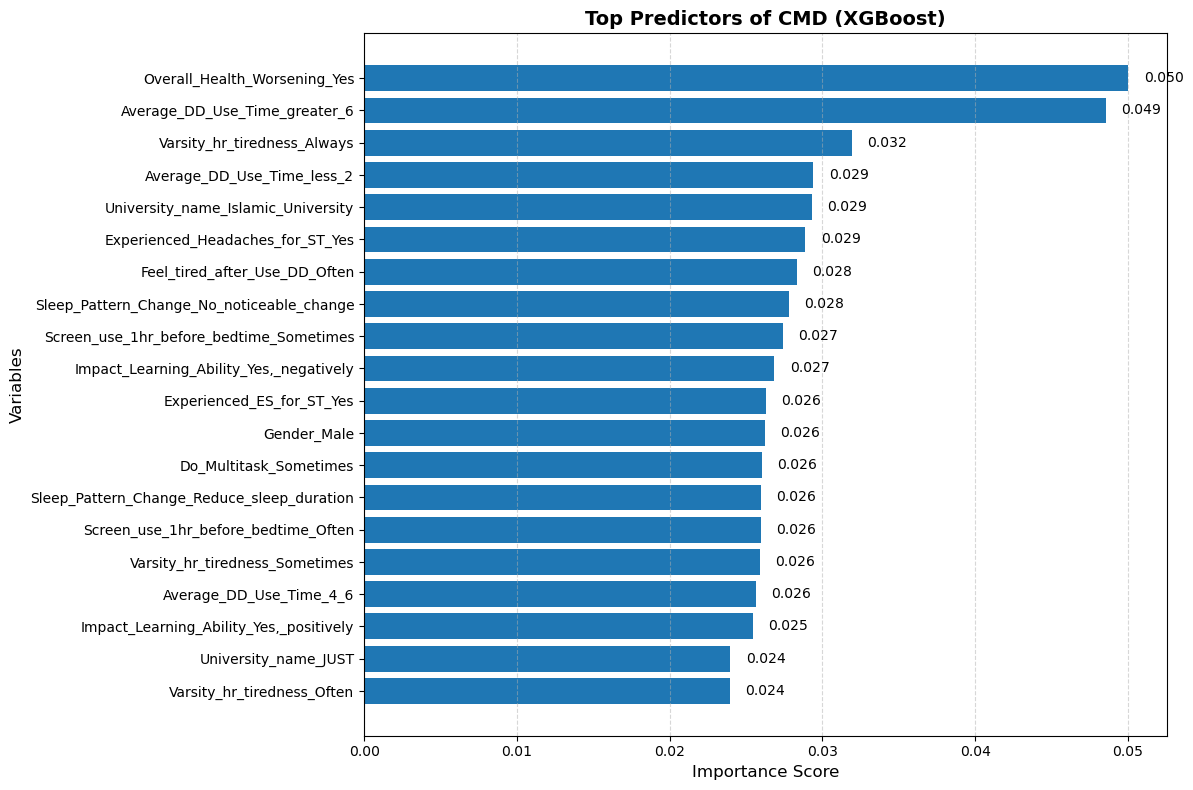

Feature importance figure exported.


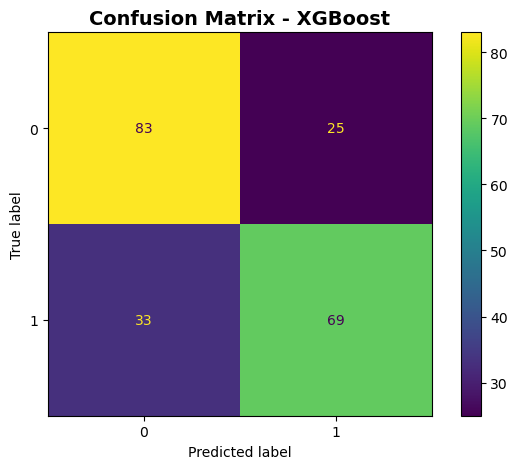

Confusion matrix figure exported.

ALL XGBOOST RESULTS EXPORTED SUCCESSFULLY


EXPORTED XGBOOST FILES

CSV FILES:
1. XGBoost_CMD_Feature_Importance.csv
2. XGBoost_Top20_CMD_Predictors.csv
3. XGBoost_Model_Performance.csv
4. XGBoost_Classification_Report.csv
5. XGBoost_Confusion_Matrix.csv
6. XGBoost_CrossValidation_Results.csv
7. XGBoost_Best_Parameters.csv

EXCEL FILE:
8. XGBoost_CMD_Full_Results.xlsx

FIGURES:
9. XGBoost_Top20_CMD_Predictors.png
10. XGBoost_Confusion_Matrix.png

SAVE LOCATION

G:\Documents\Book\1\4th Year\4th\1822021 (Project)\Results


In [12]:
# =========================================================
# EXPORT XGBOOST RESULTS + FIGURES
# PUBLICATION-QUALITY OUTPUTS
# =========================================================

import os
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (

    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

# =========================================================
# 1. DEFINE OUTPUT DIRECTORY
# =========================================================

OUTPUT_DIR = r'G:\Documents\Book\1\4th Year\4th\1822021 (Project)\Results'

os.makedirs(OUTPUT_DIR, exist_ok=True)

print("\nRESULTS WILL BE SAVED IN:")

print(OUTPUT_DIR)


# =========================================================
# 2. SAVE FEATURE IMPORTANCE TABLE
# =========================================================

importance_df.to_csv(

    os.path.join(

        OUTPUT_DIR,

        'XGBoost_CMD_Feature_Importance.csv'
    ),

    index=False
)

print("\nFeature importance table saved.")


# =========================================================
# 3. SAVE TOP 20 PREDICTORS
# =========================================================

top20 = importance_df.head(20)

top20.to_csv(

    os.path.join(

        OUTPUT_DIR,

        'XGBoost_Top20_CMD_Predictors.csv'
    ),

    index=False
)

print("Top 20 predictors saved.")


# =========================================================
# 4. SAVE MODEL PERFORMANCE
# =========================================================

performance_df = pd.DataFrame({

    'Metric': [

        'Accuracy',
        'Mean_CV_Accuracy'
    ],

    'Value': [

        accuracy,
        cv_scores.mean()
    ]
})

performance_df.to_csv(

    os.path.join(

        OUTPUT_DIR,

        'XGBoost_Model_Performance.csv'
    ),

    index=False
)

print("Model performance saved.")


# =========================================================
# 5. SAVE CLASSIFICATION REPORT
# =========================================================

report_dict = classification_report(

    y_test,
    y_pred,

    output_dict=True
)

report_df = pd.DataFrame(report_dict).transpose()

report_df.to_csv(

    os.path.join(

        OUTPUT_DIR,

        'XGBoost_Classification_Report.csv'
    )
)

print("Classification report saved.")


# =========================================================
# 6. SAVE CONFUSION MATRIX TABLE
# =========================================================

cm = confusion_matrix(

    y_test,
    y_pred
)

cm_df = pd.DataFrame(

    cm,

    columns=[

        'Predicted_No_CMD',
        'Predicted_CMD'
    ],

    index=[

        'Actual_No_CMD',
        'Actual_CMD'
    ]
)

cm_df.to_csv(

    os.path.join(

        OUTPUT_DIR,

        'XGBoost_Confusion_Matrix.csv'
    )
)

print("Confusion matrix table saved.")


# =========================================================
# 7. SAVE CROSS-VALIDATION RESULTS
# =========================================================

cv_df = pd.DataFrame({

    'Fold': [

        'Fold_1',
        'Fold_2',
        'Fold_3',
        'Fold_4',
        'Fold_5'
    ],

    'Accuracy': cv_scores
})

cv_df.to_csv(

    os.path.join(

        OUTPUT_DIR,

        'XGBoost_CrossValidation_Results.csv'
    ),

    index=False
)

print("Cross-validation results saved.")


# =========================================================
# 8. SAVE BEST HYPERPARAMETERS
# =========================================================

best_params_df = pd.DataFrame(

    [grid_search.best_params_]
)

best_params_df.to_csv(

    os.path.join(

        OUTPUT_DIR,

        'XGBoost_Best_Parameters.csv'
    ),

    index=False
)

print("Best hyperparameters saved.")


# =========================================================
# 9. EXPORT FEATURE IMPORTANCE FIGURE
# =========================================================

plt.figure(figsize=(12,8))

plt.barh(

    top20['Variable'],
    top20['Importance']
)


# Add labels

for index, value in enumerate(top20['Importance']):

    plt.text(

        value + 0.001,
        index,

        f'{value:.3f}',

        va='center',
        fontsize=10
    )


plt.xlabel(

    'Importance Score',
    fontsize=12
)

plt.ylabel(

    'Variables',
    fontsize=12
)

plt.title(

    'Top Predictors of CMD (XGBoost)',

    fontsize=14,
    fontweight='bold'
)

plt.gca().invert_yaxis()

plt.grid(

    axis='x',
    linestyle='--',
    alpha=0.5
)

plt.tight_layout()

plt.savefig(

    os.path.join(

        OUTPUT_DIR,

        'XGBoost_Top20_CMD_Predictors.png'
    ),

    dpi=300,
    bbox_inches='tight'
)

plt.show()

print("Feature importance figure exported.")


# =========================================================
# 10. EXPORT CONFUSION MATRIX FIGURE
# =========================================================

disp = ConfusionMatrixDisplay(

    confusion_matrix=cm
)

disp.plot()

plt.title(

    'Confusion Matrix - XGBoost',

    fontsize=14,
    fontweight='bold'
)

plt.tight_layout()

plt.savefig(

    os.path.join(

        OUTPUT_DIR,

        'XGBoost_Confusion_Matrix.png'
    ),

    dpi=300,
    bbox_inches='tight'
)

plt.show()

print("Confusion matrix figure exported.")


# =========================================================
# 11. SAVE ALL RESULTS INTO EXCEL
# =========================================================

excel_path = os.path.join(

    OUTPUT_DIR,

    'XGBoost_CMD_Full_Results.xlsx'
)

with pd.ExcelWriter(excel_path) as writer:

    importance_df.to_excel(

        writer,
        sheet_name='Feature_Importance',
        index=False
    )

    top20.to_excel(

        writer,
        sheet_name='Top20_Predictors',
        index=False
    )

    performance_df.to_excel(

        writer,
        sheet_name='Model_Performance',
        index=False
    )

    report_df.to_excel(

        writer,
        sheet_name='Classification_Report'
    )

    cm_df.to_excel(

        writer,
        sheet_name='Confusion_Matrix'
    )

    cv_df.to_excel(

        writer,
        sheet_name='CrossValidation',
        index=False
    )

    best_params_df.to_excel(

        writer,
        sheet_name='Best_Parameters',
        index=False
    )

print("\nALL XGBOOST RESULTS EXPORTED SUCCESSFULLY")


# =========================================================
# 12. FINAL OUTPUT SUMMARY
# =========================================================

print("""

===================================
EXPORTED XGBOOST FILES
===================================

CSV FILES:
1. XGBoost_CMD_Feature_Importance.csv
2. XGBoost_Top20_CMD_Predictors.csv
3. XGBoost_Model_Performance.csv
4. XGBoost_Classification_Report.csv
5. XGBoost_Confusion_Matrix.csv
6. XGBoost_CrossValidation_Results.csv
7. XGBoost_Best_Parameters.csv

EXCEL FILE:
8. XGBoost_CMD_Full_Results.xlsx

FIGURES:
9. XGBoost_Top20_CMD_Predictors.png
10. XGBoost_Confusion_Matrix.png

===================================
SAVE LOCATION
===================================

""" + OUTPUT_DIR)